In [1]:
package EvenUpMockups {
    doc /* Мокапы пользовательского интерфейса веб-приложения EvenUp (SRS v0.1, раздел 3.1.1).
         * Экран — part-usage типа Screen, вложенные части — элементы интерфейса.
         * Порядок вложенных частей задаёт порядок отображения: сверху вниз,
         * или слева направо, если у контейнера layout = "row". */

    // ================================================================
    // Библиотека элементов интерфейса
    // ================================================================
    package UI {
        private import ScalarValues::*;

        abstract part def Widget {
            attribute label : String default "";
            attribute style : String default "normal";   // normal | heading | muted | positive | negative | error | primary | danger
            attribute enabled : Boolean default true;
        }

        abstract part def Container :> Widget {
            attribute layout : String default "column";  // column | row
        }

        part def Screen :> Container {
            attribute route : String;                     // адрес страницы
            attribute currentUser : String default "";    // кто вошёл в систему (пусто — гость)
        }
        part def Panel :> Container;
        part def TabBar :> Container;
        part def ListView :> Container;

        part def Label :> Widget;
        part def Button :> Widget;
        part def Link :> Widget;

        part def TextField :> Widget {
            attribute value : String default "";
            attribute placeholder : String default "";
            attribute readOnly : Boolean default false;
        }
        part def PasswordField :> TextField;
        part def DateField :> TextField;
        part def ComboBox :> TextField;

        part def CheckBox :> Widget {
            attribute checked : Boolean default false;
        }
        part def RadioButton :> CheckBox;

        part def Tab :> Widget {
            attribute selected : Boolean default false;
        }

        part def ListItem :> Widget {
            attribute value : String default "";
            attribute details : String default "";
        }
    }

    // ================================================================
    // Экраны
    // ================================================================
    package Screens {
        private import EvenUpMockups::UI::*;

        // ---------- UI-01. Вход / регистрация (REQ-FUNC-001, 002) ----------
        part loginScreen : Screen {
            :>> label = "Вход";
            :>> route = "/login";

            part authTabs : TabBar {
                :>> layout = "row";
                part tabLogin : Tab { :>> label = "Вход"; :>> selected = true; }
                part tabRegister : Tab { :>> label = "Регистрация"; }
            }
            part emailField : TextField {
                :>> label = "Email";
                :>> placeholder = "name@example.com";
            }
            part passwordField : PasswordField {
                :>> label = "Пароль";
                :>> placeholder = "Не менее 8 символов";
            }
            part errorMessage : Label {
                :>> label = "Неверный email или пароль";
                :>> style = "error";
            }
            part loginButton : Button {
                :>> label = "Войти";
                :>> style = "primary";
            }
            part registerLink : Link {
                :>> label = "Нет аккаунта? Зарегистрироваться";
            }
        }

        // ---------- UI-02. Мои группы (REQ-FUNC-003, 004) ----------
        part groupsScreen : Screen {
            :>> label = "Мои группы";
            :>> route = "/groups";
            :>> currentUser = "Аня";

            part header : Panel {
                :>> layout = "row";
                part title : Label { :>> label = "Мои группы"; :>> style = "heading"; }
                part createGroupButton : Button { :>> label = "+ Создать группу"; :>> style = "primary"; }
            }
            part groupList : ListView {
                part groupTrip : ListItem {
                    :>> label = "Поездка в Минск";
                    :>> details = "3 участника";
                    :>> value = "+50,00 BYN";
                    :>> style = "positive";
                }
                part groupFlat : ListItem {
                    :>> label = "Квартира";
                    :>> details = "4 участника";
                    :>> value = "−12,40 BYN";
                    :>> style = "negative";
                }
                part groupBirthday : ListItem {
                    :>> label = "День рождения Бориса";
                    :>> details = "6 участников";
                    :>> value = "0,00 BYN";
                }
            }
            part archiveSection : Link {
                :>> label = "Архив (2) — показать";
            }
        }

        // ---------- UI-03. Группа → Траты (REQ-FUNC-011, 019, 020) ----------
        part expensesScreen : Screen {
            :>> label = "Поездка в Минск — Траты";
            :>> route = "/groups/{id}/expenses";
            :>> currentUser = "Аня";

            part backLink : Link { :>> label = "← Мои группы"; }
            part groupTitle : Label { :>> label = "Поездка в Минск"; :>> style = "heading"; }
            part groupTabs : TabBar {
                :>> layout = "row";
                part tabExpenses : Tab { :>> label = "Траты"; :>> selected = true; }
                part tabBalances : Tab { :>> label = "Балансы"; }
                part tabMembers : Tab { :>> label = "Участники"; }
                part tabHistory : Tab { :>> label = "История"; }
            }
            part toolbar : Panel {
                :>> layout = "row";
                part memberFilter : ComboBox { :>> label = "Участник"; :>> value = "Все"; }
                part addExpenseButton : Button { :>> label = "+ Добавить трату"; :>> style = "primary"; }
            }
            part expenseList : ListView {
                part expenseDinner : ListItem {
                    :>> label = "Ужин";
                    :>> details = "Платил Борис · 13.10.2026 · на 3 чел.";
                    :>> value = "30,00 BYN";
                }
                part expenseFlat : ListItem {
                    :>> label = "Жильё";
                    :>> details = "Платила Аня · 12.10.2026 · на 3 чел.";
                    :>> value = "90,00 BYN";
                }
            }
        }

        // ---------- UI-04. Форма траты (REQ-FUNC-011, 012, 013) ----------
        part expenseFormScreen : Screen {
            :>> label = "Новая трата";
            :>> route = "/groups/{id}/expenses/new";
            :>> currentUser = "Аня";

            part descriptionField : TextField { :>> label = "Описание"; :>> value = "Ужин"; }
            part amountRow : Panel {
                :>> layout = "row";
                part amountField : TextField { :>> label = "Сумма, BYN"; :>> value = "30,00"; }
                part dateField : DateField { :>> label = "Дата"; :>> value = "13.10.2026"; }
            }
            part payerField : ComboBox { :>> label = "Кто платил"; :>> value = "Борис"; }
            part splitPanel : Panel {
                :>> label = "Делить поровну между";
                part splitAnya : CheckBox { :>> label = "Аня"; :>> checked = true; }
                part splitBoris : CheckBox { :>> label = "Борис"; :>> checked = true; }
                part splitVika : CheckBox { :>> label = "Вика (без аккаунта)"; :>> checked = true; }
                part shareHint : Label { :>> label = "По 10,00 BYN на каждого"; :>> style = "muted"; }
            }
            part formButtons : Panel {
                :>> layout = "row";
                part cancelButton : Button { :>> label = "Отмена"; }
                part saveButton : Button { :>> label = "Сохранить"; :>> style = "primary"; }
            }
        }

        // ---------- UI-05. Группа → Балансы (REQ-FUNC-014, 015, 016) ----------
        part balancesScreen : Screen {
            :>> label = "Поездка в Минск — Балансы";
            :>> route = "/groups/{id}/balances";
            :>> currentUser = "Аня";

            part backLink : Link { :>> label = "← Мои группы"; }
            part groupTitle : Label { :>> label = "Поездка в Минск"; :>> style = "heading"; }
            part groupTabs : TabBar {
                :>> layout = "row";
                part tabExpenses : Tab { :>> label = "Траты"; }
                part tabBalances : Tab { :>> label = "Балансы"; :>> selected = true; }
                part tabMembers : Tab { :>> label = "Участники"; }
                part tabHistory : Tab { :>> label = "История"; }
            }
            part balanceList : ListView {
                :>> label = "Балансы участников";
                part balanceAnya : ListItem { :>> label = "Аня"; :>> value = "+50,00 BYN"; :>> style = "positive"; }
                part balanceBoris : ListItem { :>> label = "Борис"; :>> value = "−10,00 BYN"; :>> style = "negative"; }
                part balanceVika : ListItem { :>> label = "Вика"; :>> value = "−40,00 BYN"; :>> style = "negative"; }
            }
            part transferList : Panel {
                :>> label = "Кто кому переводит";
                part transfer1 : Panel {
                    :>> layout = "row";
                    part transfer1Text : Label { :>> label = "Вика → Аня: 40,00 BYN"; }
                    part transfer1Done : Button { :>> label = "Отметить выполненным"; }
                }
                part transfer2 : Panel {
                    :>> layout = "row";
                    part transfer2Text : Label { :>> label = "Борис → Аня: 10,00 BYN"; }
                    part transfer2Done : Button { :>> label = "Отметить выполненным"; }
                }
            }
            part manualSettlementButton : Button {
                :>> label = "Записать перевод вручную";
            }
        }

        // ---------- UI-06. Группа → Участники (REQ-FUNC-006, 008, 010) ----------
        part membersScreen : Screen {
            :>> label = "Поездка в Минск — Участники";
            :>> route = "/groups/{id}/members";
            :>> currentUser = "Аня";

            part backLink : Link { :>> label = "← Мои группы"; }
            part groupTitle : Label { :>> label = "Поездка в Минск"; :>> style = "heading"; }
            part groupTabs : TabBar {
                :>> layout = "row";
                part tabExpenses : Tab { :>> label = "Траты"; }
                part tabBalances : Tab { :>> label = "Балансы"; }
                part tabMembers : Tab { :>> label = "Участники"; :>> selected = true; }
                part tabHistory : Tab { :>> label = "История"; }
            }
            part memberList : ListView {
                :>> label = "Участники (3 из 30)";
                part memberAnya : ListItem { :>> label = "Аня"; :>> details = "Создатель группы"; }
                part memberBoris : ListItem { :>> label = "Борис"; :>> value = "Удалить"; }
                part memberVika : ListItem {
                    :>> label = "Вика";
                    :>> details = "Без аккаунта · баланс не нулевой — удалить нельзя";
                    :>> value = "Удалить";
                    :>> enabled = false;
                }
            }
            part invitePanel : Panel {
                :>> label = "Ссылка-приглашение";
                part inviteLink : TextField {
                    :>> value = "https://evenup.local/join/7f3a…";
                    :>> readOnly = true;
                }
                part inviteButtons : Panel {
                    :>> layout = "row";
                    part copyButton : Button { :>> label = "Скопировать"; :>> style = "primary"; }
                    part regenerateButton : Button { :>> label = "Перевыпустить"; }
                }
            }
            part addVirtualPanel : Panel {
                :>> label = "Добавить участника без аккаунта";
                :>> layout = "row";
                part virtualNameField : TextField { :>> placeholder = "Имя"; }
                part addVirtualButton : Button { :>> label = "Добавить"; }
            }
        }

        // ---------- UI-07. Группа → История (REQ-FUNC-018) ----------
        part historyScreen : Screen {
            :>> label = "Поездка в Минск — История";
            :>> route = "/groups/{id}/history";
            :>> currentUser = "Аня";

            part backLink : Link { :>> label = "← Мои группы"; }
            part groupTitle : Label { :>> label = "Поездка в Минск"; :>> style = "heading"; }
            part groupTabs : TabBar {
                :>> layout = "row";
                part tabExpenses : Tab { :>> label = "Траты"; }
                part tabBalances : Tab { :>> label = "Балансы"; }
                part tabMembers : Tab { :>> label = "Участники"; }
                part tabHistory : Tab { :>> label = "История"; :>> selected = true; }
            }
            part historyList : ListView {
                part event4 : ListItem {
                    :>> label = "Борис добавил трату «Ужин» — 30,00 BYN";
                    :>> details = "13.10.2026 21:40";
                }
                part event3 : ListItem {
                    :>> label = "Аня добавила трату «Жильё» — 90,00 BYN";
                    :>> details = "12.10.2026 15:05";
                }
                part event2 : ListItem {
                    :>> label = "Аня добавила участника Вика (без аккаунта)";
                    :>> details = "12.10.2026 15:01";
                }
                part event1 : ListItem {
                    :>> label = "Борис вступил в группу";
                    :>> details = "12.10.2026 14:58";
                }
            }
        }

        // ---------- UI-08. Вступление в группу (REQ-FUNC-007, 009) ----------
        part joinScreen : Screen {
            :>> label = "Приглашение в группу";
            :>> route = "/join/{token}";
            :>> currentUser = "Вика";

            part inviteTitle : Label {
                :>> label = "Вас пригласили в группу «Поездка в Минск»";
                :>> style = "heading";
            }
            part inviteInfo : Label {
                :>> label = "Создатель: Аня · 3 участника · валюта BYN";
                :>> style = "muted";
            }
            part identityPanel : Panel {
                :>> label = "Кто вы в этой группе?";
                part newMemberOption : RadioButton { :>> label = "Я новый участник"; }
                part claimVikaOption : RadioButton {
                    :>> label = "Я — Вика (участник без аккаунта)";
                    :>> checked = true;
                }
            }
            part joinButtons : Panel {
                :>> layout = "row";
                part declineButton : Button { :>> label = "Отказаться"; }
                part joinButton : Button { :>> label = "Вступить"; :>> style = "primary"; }
            }
        }
    }

    // ================================================================
    // Навигация между экранами
    // ================================================================
    package Navigation {
        doc /* Состояние — открытый экран, переход — действие пользователя.
             * Вкладки группы переключаются из любой вкладки (переходы от составного состояния groupView). */

        attribute def SignIn;
        attribute def SignInWithInvite;
        attribute def SignOut;
        attribute def OpenGroup;
        attribute def BackToGroups;
        attribute def OpenInviteLink;
        attribute def JoinGroup;
        attribute def DeclineInvite;
        attribute def SelectExpensesTab;
        attribute def SelectBalancesTab;
        attribute def SelectMembersTab;
        attribute def SelectHistoryTab;
        attribute def AddExpense;
        attribute def EditExpense;
        attribute def SaveExpense;
        attribute def CancelExpense;

        state def AppNavigation {
            entry; then login;

            state login;      // UI-01
            state groups;     // UI-02
            state invitation; // UI-08

            state groupView {
                entry; then expenses;

                state expenses;      // UI-03
                state expenseForm;   // UI-04
                state balances;      // UI-05
                state members;       // UI-06
                state history;       // UI-07

                transition addExpense first expenses accept AddExpense then expenseForm;
                transition editExpense first expenses accept EditExpense then expenseForm;
                transition saveExpense first expenseForm accept SaveExpense then expenses;
                transition cancelExpense first expenseForm accept CancelExpense then expenses;
            }

            transition signIn first login accept SignIn then groups;
            transition signInWithInvite first login accept SignInWithInvite then invitation;
            transition signOut first groups accept SignOut then login;
            transition openGroup first groups accept OpenGroup then groupView;
            transition openInvite first groups accept OpenInviteLink then invitation;
            transition joinGroup first invitation accept JoinGroup then groupView;
            transition declineInvite first invitation accept DeclineInvite then groups;
            transition backToGroups first groupView accept BackToGroups then groups;

            transition toExpenses first groupView accept SelectExpensesTab then groupView.expenses;
            transition toBalances first groupView accept SelectBalancesTab then groupView.balances;
            transition toMembers first groupView accept SelectMembersTab then groupView.members;
            transition toHistory first groupView accept SelectHistoryTab then groupView.history;
        }
    }
}


Package EvenUpMockups (c8f1f6d1-bb63-4f38-8148-0fbfcc15b142)


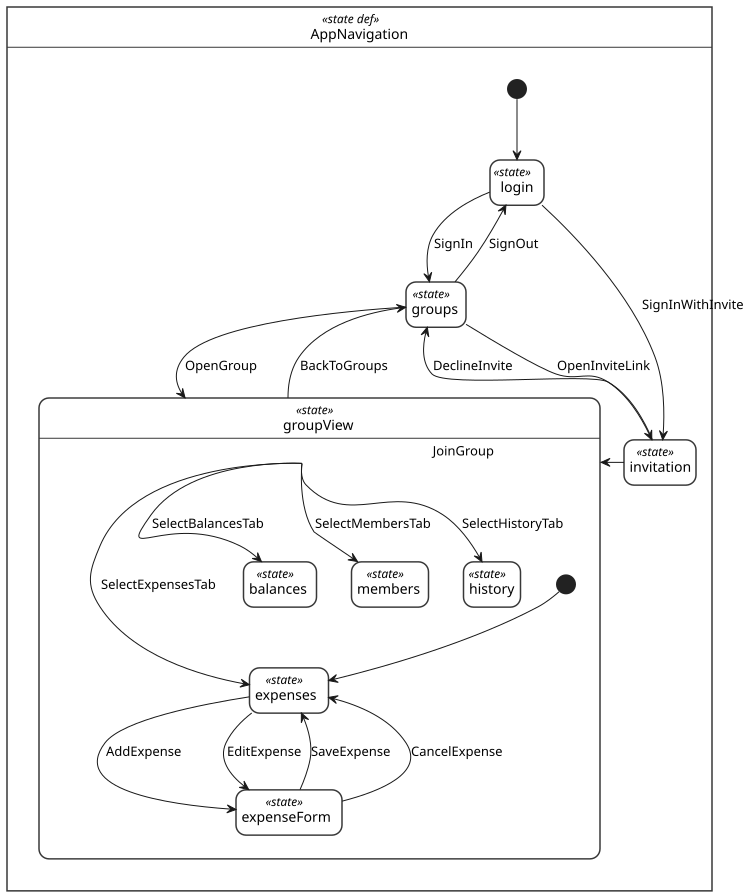

In [2]:
%viz --view=State EvenUpMockups::Navigation::AppNavigation